# CLIMATE CHANGE DATA ANALYSIS

### Project Overview

This project analyses climate-related data from 20 different
locations using Python.

### Tools and Libraries
- Python
- Pandas
- Matplotlib
- Jupyter Notebook

### Dataset Information
- Total Records: 240
- Total Locations: 20
- Time Period: 2024–2025

### Project Objectives
1. Analyse temperature variations.
2. Examine rainfall patterns.
3. Study humidity and wind speed.
4. Analyse extreme weather conditions.
5. Explore relationships between climate variables.
6. Visualise climate data using graphs.

## 1. Importing Libraries and Loading the Dataset

In this section, we import the Python libraries required for data analysis and visualisation. We then load the raw climate dataset into a Pandas DataFrame named `df`.

The initial inspection displays the dataset's structure, column data types, and missing-value counts.


In [1]:
# Import libraries, load the raw dataset, and inspect its structure

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df= pd.read_csv("climate_change_new1.csv")
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Date                 240 non-null    str    
 1   Country / Location   240 non-null    str    
 2   Average Temperature  222 non-null    float64
 3   Rainfall             223 non-null    float64
 4   Humidity             240 non-null    str    
 5   Wind Speed           240 non-null    str    
 6   CO2 Level            240 non-null    float64
 7   Extreme Weather      185 non-null    str    
 8   Data Type            240 non-null    str    
 9   Source / Notes       240 non-null    str    
dtypes: float64(3), str(7)
memory usage: 18.9 KB


Date                    0
Country / Location      0
Average Temperature    18
Rainfall               17
Humidity                0
Wind Speed              0
CO2 Level               0
Extreme Weather        55
Data Type               0
Source / Notes          0
dtype: int64

## 2. Handling Missing Values and Extreme Weather Entries

We begin preprocessing by handling missing values in selected columns:

- Missing average temperatures are replaced with the column median.
- Missing rainfall values are replaced with the column median.
- Missing extreme-weather entries are labelled `Not Recorded`.

We also standardise entries written as `na` so they use the same `Not Recorded` label.


In [2]:
# Fill missing temperature and rainfall values and label missing weather records

df['Average Temperature'] = df['Average Temperature'].fillna(
    df['Average Temperature'].median()
)

df['Rainfall'] = df['Rainfall'].fillna(
    df['Rainfall'].median()
)

df['Extreme Weather'] = df['Extreme Weather'].fillna('Not Recorded')

In [3]:
# Recheck data types, missing values, and extreme-weather categories

df.info()
df.isnull().sum()
df['Extreme Weather'].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Date                 240 non-null    str    
 1   Country / Location   240 non-null    str    
 2   Average Temperature  240 non-null    float64
 3   Rainfall             240 non-null    float64
 4   Humidity             240 non-null    str    
 5   Wind Speed           240 non-null    str    
 6   CO2 Level            240 non-null    float64
 7   Extreme Weather      240 non-null    str    
 8   Data Type            240 non-null    str    
 9   Source / Notes       240 non-null    str    
dtypes: float64(3), str(7)
memory usage: 18.9 KB


Extreme Weather
Not Recorded    55
Storm           48
Flood           40
Drought         36
Heatwave        33
Heavy rain      27
na               1
Name: count, dtype: int64

In [4]:
# Standardise na entries in the Extreme Weather column

df['Extreme Weather'] = df['Extreme Weather'].replace(
    r'(?i)^\s*na\s*$',
    'Not Recorded',
    regex=True
)

In [5]:
# Verify the updated extreme-weather categories

df['Extreme Weather'].value_counts()

Extreme Weather
Not Recorded    56
Storm           48
Flood           40
Drought         36
Heatwave        33
Heavy rain      27
Name: count, dtype: int64

## 3. Cleaning the Humidity Column

The humidity column contains values written in different formats, including numbers with a percent sign.

We remove the percent sign, remove extra spaces, and convert the column to a numeric data type. We then inspect the cleaned values before handling any missing entries.


In [6]:
# Inspect the original humidity and wind-speed formats

print(df['Humidity'].unique())
print(df['Wind Speed'].unique())

<StringArray>
[  '95',   '49',   '77',  '86%',   '57',   '85',   '83',   '47',   '68',
   '27',   '67',   '58',   '70',   '74',   '66',  '55%',   '54',   '69',
   '59',   '89',   '48',   '81',   '51',   '62',   '61',   '60',   '56',
   '82',   '76',   '53',   '43',   '71',   '46',   '65',   '86',   '55',
  '62%',   '25',  '47%',   '75',   '79',   '98',   '50',   '52',  '74%',
  '100',   'na',   '72',   '63',   '80',   '99',   '44',  '85%',   '73',
   '64',   '90',  '77%',   '84',   '88',   '26',   '41',   '91',   '97',
   '87',   '42',  '48%',   '78', '100%',  '97%',   '31',   '45',   '92']
Length: 72, dtype: str
<StringArray>
[     '14.2',      '13.1',      '24.3',      '18.7',      '18.6',         '8',
      '11.3', '13.6 km/h',      '20.8',   '3.5 m/s',
 ...
      '14.6',       '5.7',         '3',      '30.6',      '10.5', '15.9 km/h',
      '19.1',       '7.4',      '28.8',       '6.5']
Length: 147, dtype: str


In [7]:
# Remove percent signs and convert humidity values to numeric

df['Humidity'] = (
    df['Humidity']
    .astype(str)
    .str.replace('%', '', regex=False)
    .str.strip()
)

df['Humidity'] = pd.to_numeric(df['Humidity'], errors='coerce')

In [8]:
# Check the cleaned humidity values and data type

print(df['Humidity'].head(20))
print(df['Humidity'].dtype)

0     95.0
1     49.0
2     77.0
3     86.0
4     57.0
5     85.0
6     83.0
7     47.0
8     68.0
9     27.0
10    67.0
11    58.0
12    70.0
13    74.0
14    66.0
15    55.0
16    54.0
17    69.0
18    85.0
19    59.0
Name: Humidity, dtype: float64
float64


## 4. Cleaning and Standardising Wind Speed

Wind speed values use more than one format. Some values are recorded in `km/h`, while others are recorded in `m/s`.

To make the column consistent, we remove the unit text, convert the values to numbers, and convert metres per second to kilometres per hour using the conversion factor 3.6.


In [9]:
wind = df['Wind Speed'].astype(str).str.strip()

# Remove units and convert m/s values to km/h
wind_clean = pd.to_numeric(
    wind.str.replace('km/h', '', regex=False)
        .str.replace('m/s', '', regex=False)
        .str.strip(),
    errors='coerce'
)

# Convert m/s values to km/h
ms_mask = wind.str.contains('m/s', case=False, na=False)

wind_clean.loc[ms_mask] = wind_clean.loc[ms_mask] * 3.6

# Replace original column with cleaned numeric values
df['Wind Speed'] = wind_clean

In [10]:
# Check the cleaned wind-speed values and identify missing entries

print(df['Wind Speed'].head(20))
print(df['Wind Speed'].dtype)
print("Missing Values: ", df['Wind Speed'].isnull().sum())

0     14.2
1     13.1
2     24.3
3     18.7
4     18.6
5      8.0
6     11.3
7     13.6
8     20.8
9     12.6
10     9.9
11    19.3
12    23.4
13    18.6
14    21.9
15    13.7
16    15.0
17    21.8
18    29.1
19    10.2
Name: Wind Speed, dtype: float64
float64
Missing Values:  10


In [11]:
# Refer to the original dataset to inspect wind-speed entries that became missing

df_raw = pd.read_csv('climate_change_new1.csv')

missing_wind = df['Wind Speed'].isna()

print(df_raw.loc[missing_wind, ['Wind Speed']])

    Wind Speed
71          na
75          na
110         na
118         na
154         na
167         na
174         na
184         na
186         na
202         na


In [12]:
# Fill missing wind-speed values using the column median

df['Wind Speed'] = df['Wind Speed'].fillna(
    df['Wind Speed'].median()
)

In [13]:
# Verify that no wind-speed values remain missing

print("Missing Values: ", df['Wind Speed'].isnull().sum())
print("Median")

Missing Values:  0
Median


## 5. Handling Missing Humidity Values

After converting humidity to numeric values, entries that could not be converted are treated as missing.

We inspect the corresponding original entries and fill missing humidity values using the median of the cleaned humidity column.


In [14]:
# Inspect original humidity entries corresponding to missing values

humidity_missing = df['Humidity'].isna()

print(df_raw.loc[humidity_missing, ['Humidity']])

    Humidity
71        na
75        na
110       na
118       na
154       na
167       na
174       na
184       na
186       na
202       na


In [15]:
# Fill missing humidity values using the column median

df['Humidity']= df['Humidity'].fillna(df['Humidity'].median())

In [16]:
# Confirm that humidity has no remaining missing values

print(df['Humidity'].isnull().sum())

0


## 6. Converting the Date Column

The date column needs to use a consistent datetime data type so records can be sorted chronologically and grouped by month.

We convert the column using Pandas and check the resulting data type.


In [17]:
# Convert Date values to Pandas datetime format

df['Date']= pd.to_datetime(df['Date'], errors='coerce')

In [18]:
# Verify the Date column data type

print(df['Date'].dtype)

datetime64[us]


## 7. Checking Duplicates and Standardising Location Names

We check for duplicate rows and standardise location names by removing leading or trailing spaces and applying consistent title case.

The dataset is then sorted alphabetically by location and chronologically by date. A cleaned Excel copy is saved for reference.


In [19]:
# Count duplicate rows in the dataset

df.duplicated().sum()

np.int64(0)

In [20]:
# Standardize country names
df['Country / Location'] = (
    df['Country / Location']
    .str.strip()
    .str.title()
)

# Arrange countries alphabetically and dates chronologically
df = df.sort_values(
    by=['Country / Location', 'Date']
).reset_index(drop=True)

# Save updated cleaned dataset
df.to_excel("Cleaned_Climate_Data.xlsx", index=False)

# Display the result
display(df[['Country / Location', 'Date']].head(20))

,Country / Location,Date
0,Argentina,2025-01-01
1,Argentina,2025-02-01
2,Argentina,2025-03-01
3,Argentina,2025-04-01
4,Argentina,2025-05-01
5,Argentina,2025-06-01
6,Argentina,2025-07-01
7,Argentina,2025-08-01
8,Argentina,2025-09-01
9,Argentina,2025-10-01


## 8. Validating the Cleaned Dataset

Before beginning analysis, we perform a few checks:

- Confirm the working directory used for saved files.
- Count records for each location.
- Review the date range and number of records per location.
- Inspect the Mauna Loa Observatory, Hawaii records separately.

These checks help us understand the coverage of the dataset.


In [21]:
# Count the number of records for each location

df['Country / Location'].value_counts()

Country / Location
Argentina                        12
Australia                        12
Bangladesh                       12
Brazil                           12
Canada                           12
China                            12
Egypt                            12
France                           12
Germany                          12
India                            12
Indonesia                        12
Italy                            12
Japan                            12
Kenya                            12
Mauna Loa Observatory, Hawaii    12
Mexico                           12
Russia                           12
South Africa                     12
United Kingdom                   12
United States                    12
Name: count, dtype: int64

In [22]:
# Check the date range and record count for each location

df.groupby('Country / Location')['Date'].agg(['min','max','count'])

,min,max,count
Country / Location,,,
Argentina,2025-01-01,2025-12-01,12
Australia,2025-01-01,2025-12-01,12
Bangladesh,2025-01-01,2025-12-01,12
Brazil,2025-01-01,2025-12-01,12
Canada,2025-01-01,2025-12-01,12
China,2025-01-01,2025-12-01,12
Egypt,2025-01-01,2025-12-01,12
France,2025-01-01,2025-12-01,12
Germany,2025-01-01,2025-12-01,12


In [23]:
# Inspect the Mauna Loa Observatory, Hawaii records

df[df['Country / Location']=='Mauna Loa Observatory, Hawaii']

,Date,Country / Location,Average Temperature,Rainfall,Humidity,Wind Speed,CO2 Level,Extreme Weather,Data Type,Source / Notes
168,2024-01-01,"Mauna Loa Observatory, Hawaii",21.25,52.5,67.0,15.1,422.80,Not Recorded,Real - NOAA measurement,NOAA GML monthly mean CO2; ppm
169,2024-02-01,"Mauna Loa Observatory, Hawaii",21.25,52.5,67.0,15.1,424.55,Not Recorded,Real - NOAA measurement,NOAA GML monthly mean CO2; ppm
170,2024-03-01,"Mauna Loa Observatory, Hawaii",21.25,52.5,67.0,15.1,425.38,Not Recorded,Real - NOAA measurement,NOAA GML monthly mean CO2; ppm
171,2024-04-01,"Mauna Loa Observatory, Hawaii",21.25,52.5,67.0,15.1,426.51,Not Recorded,Real - NOAA measurement,NOAA GML monthly mean CO2; ppm
172,2024-05-01,"Mauna Loa Observatory, Hawaii",21.25,52.5,27.0,12.6,426.90,Not Recorded,Real - NOAA measurement,NOAA GML monthly mean CO2; ppm
173,2024-06-01,"Mauna Loa Observatory, Hawaii",21.25,52.5,67.0,15.1,426.91,Not Recorded,Real - NOAA measurement,NOAA GML monthly mean CO2; ppm
174,2024-07-01,"Mauna Loa Observatory, Hawaii",21.25,52.5,67.0,15.1,425.55,Not Recorded,Real - NOAA measurement,NOAA GML monthly mean CO2; ppm
175,2024-08-01,"Mauna Loa Observatory, Hawaii",21.25,52.5,67.0,15.1,422.99,Not Recorded,Real - NOAA measurement,NOAA GML monthly mean CO2; ppm
176,2024-09-01,"Mauna Loa Observatory, Hawaii",21.25,52.5,67.0,15.1,422.03,Not Recorded,Real - NOAA measurement,NOAA GML monthly mean CO2; ppm
177,2024-10-01,"Mauna Loa Observatory, Hawaii",21.25,52.5,27.0,12.6,422.38,Not Recorded,Real - NOAA measurement,NOAA GML monthly mean CO2; ppm


# 9. Data Analysis (EDA)

Data Analysis is used to examine the cleaned dataset, identify patterns, and summarise the climate variables through statistics and visualisations.

### 9.1 Average Temperature by Location

We calculate the mean temperature for each location and sort the results to compare locations.


In [24]:
# Calculate and display average temperature by location

avg_temp = df.groupby('Country / Location')['Average Temperature'].mean()

avg_temp = avg_temp.sort_values(ascending=False)

display(avg_temp)

Country / Location
Indonesia                        30.966667
India                            30.441667
Bangladesh                       30.433333
Brazil                           28.391667
Egypt                            27.400000
Australia                        26.045833
Kenya                            25.558333
Mexico                           23.870833
South Africa                     22.366667
Argentina                        21.254167
Mauna Loa Observatory, Hawaii    21.250000
Japan                            19.350000
Italy                            19.175000
France                           18.820833
China                            18.241667
United States                    17.075000
United Kingdom                   14.600000
Germany                          14.279167
Canada                            9.454167
Russia                            5.241667
Name: Average Temperature, dtype: float64

### 9.2 Visualising Average Temperature by Location

The horizontal bar chart compares the average temperature recorded at each location. Sorting the values makes it easier to identify higher and lower averages.


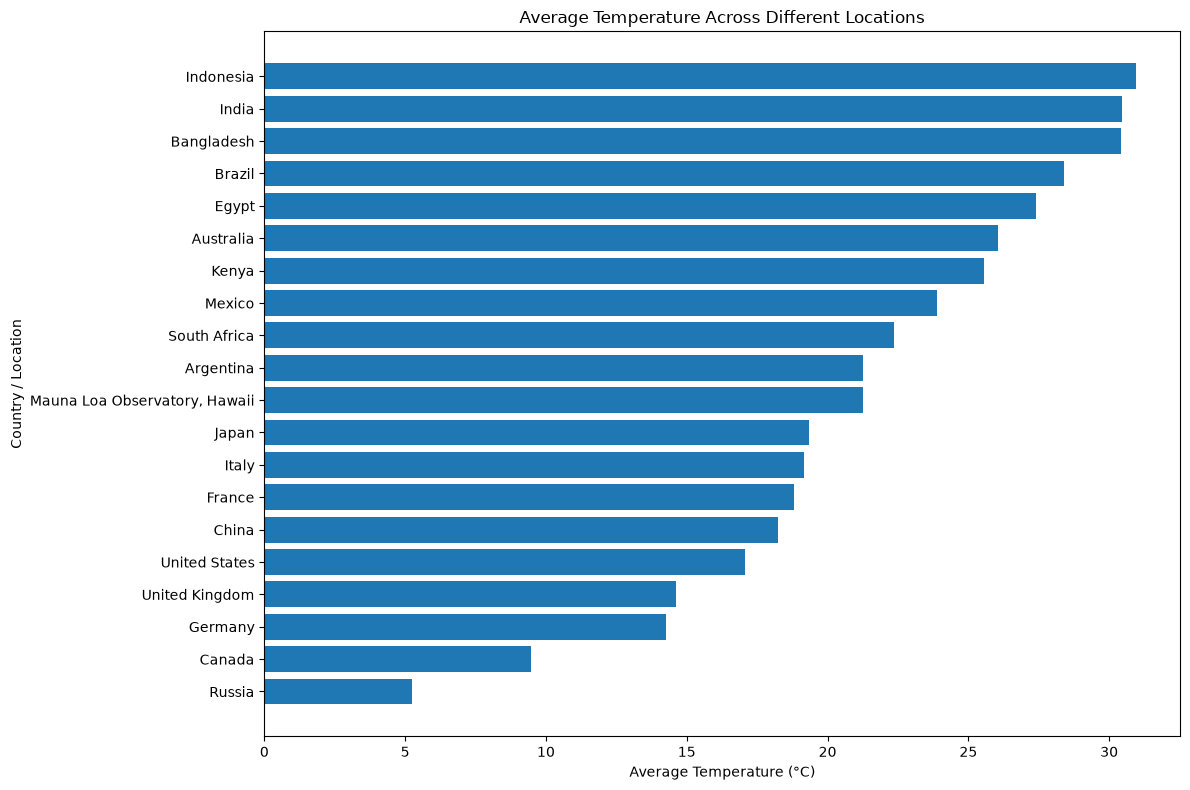

In [25]:
# Create a horizontal bar chart of average temperature by location

avg_temp = df.groupby('Country / Location')['Average Temperature'].mean()

avg_temp = avg_temp.sort_values()

plt.figure(figsize=(12, 8))

plt.barh(avg_temp.index, avg_temp.values)

plt.xlabel('Average Temperature (°C)')
plt.ylabel('Country / Location')
plt.title('Average Temperature Across Different Locations')

plt.tight_layout()
plt.show()

### 9.3 Monthly Average Temperature Trend

We create a `Month` column from the date and calculate the average temperature for each calendar month.

The month column is retained in the working dataset because it is useful for monthly analysis. The chart combines records from the different locations and years in this dataset.


In [26]:
# Create the Month column and calculate monthly average temperature

df['Month']= df['Date'].dt.month
monthly_temp= df.groupby('Month')['Average Temperature'].mean()

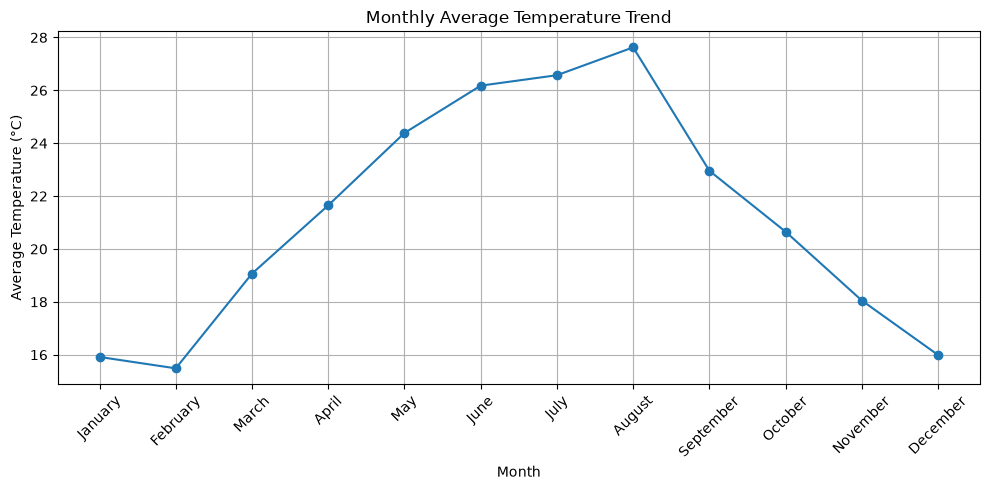

In [27]:
# Plot monthly average temperature using month names

import calendar

plt.figure(figsize=(10, 5))

plt.plot(monthly_temp.index, monthly_temp.values, marker='o')

plt.xlabel('Month')
plt.ylabel('Average Temperature (°C)')
plt.title('Monthly Average Temperature Trend')

plt.xticks(
    range(1, 13),
    [calendar.month_name[i] for i in range(1, 13)],
    rotation=45
)

plt.grid(True)
plt.tight_layout()
plt.show()

### 9.4 Rainfall Analysis

We calculate average rainfall for each location and visualise the differences with a horizontal bar chart. We also calculate the average rainfall for each calendar month to explore monthly variation across the records.


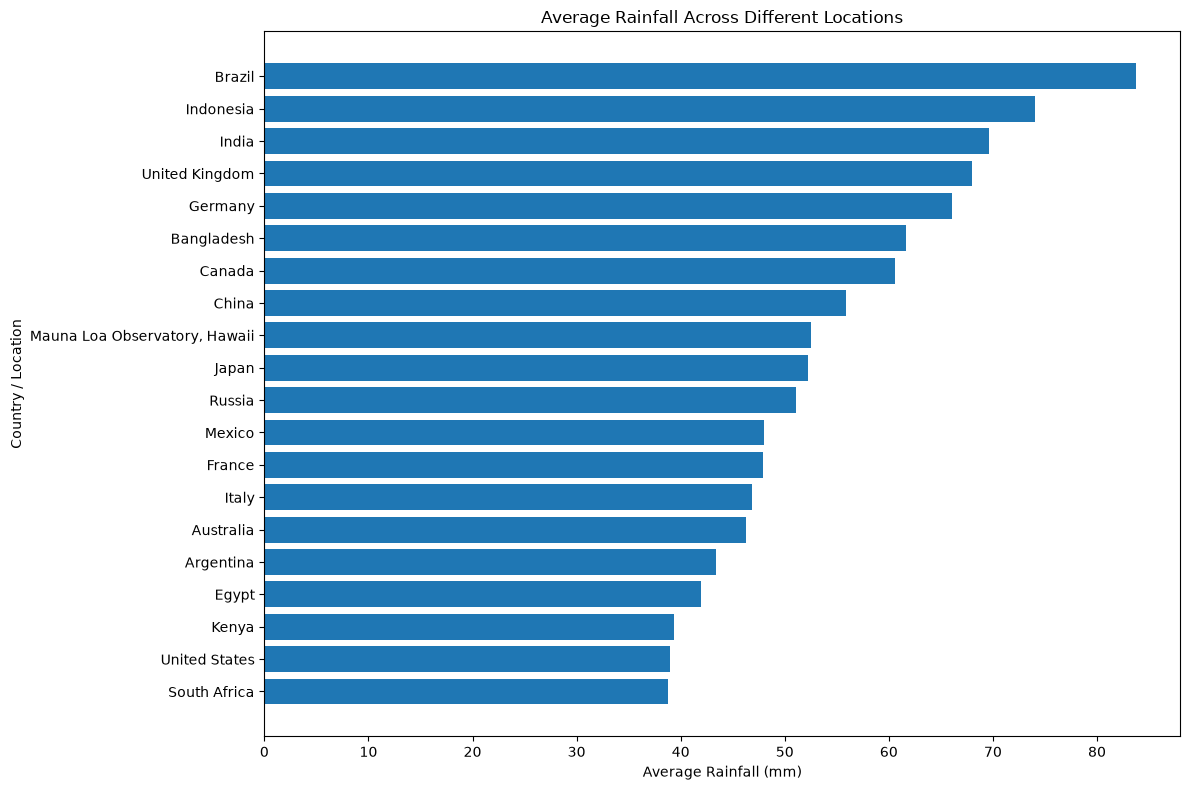

In [28]:
# Calculate and plot average rainfall by location

avg_rainfall = df.groupby('Country / Location')['Rainfall'].mean()
avg_rainfall = avg_rainfall.sort_values()

plt.figure(figsize=(12, 8))
plt.barh(avg_rainfall.index, avg_rainfall.values)

plt.xlabel('Average Rainfall (mm)')
plt.ylabel('Country / Location')
plt.title('Average Rainfall Across Different Locations')

plt.tight_layout()
plt.show()

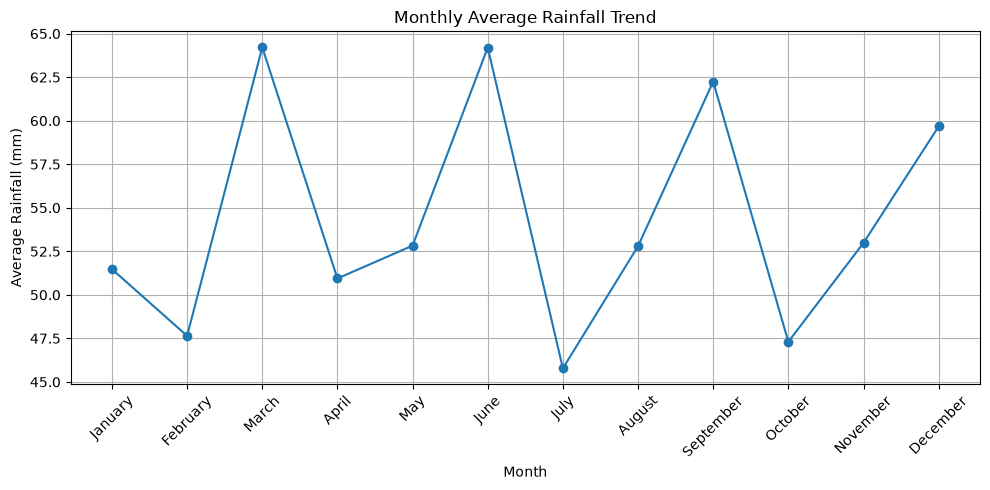

In [29]:
# Calculate and plot monthly average rainfall

monthly_rainfall = df.groupby('Month')['Rainfall'].mean()

plt.figure(figsize=(10, 5))

plt.plot(monthly_rainfall.index, monthly_rainfall.values, marker='o')

plt.xlabel('Month')
plt.ylabel('Average Rainfall (mm)')
plt.title('Monthly Average Rainfall Trend')

plt.xticks(
    range(1, 13),
    [calendar.month_name[i] for i in range(1, 13)],
    rotation=45
)

plt.grid(True)
plt.tight_layout()
plt.show()

### 9.5 Extreme Weather Analysis

We count the recorded categories in the `Extreme Weather` column and visualise their frequencies.

The category `Not Recorded` represents unavailable weather information, not an actual extreme-weather event. It should therefore be distinguished when interpreting event frequencies.


In [30]:
# Count the recorded extreme-weather categories

weather_counts = df['Extreme Weather'].value_counts()

display(weather_counts)

Extreme Weather
Not Recorded    56
Storm           48
Flood           40
Drought         36
Heatwave        33
Heavy rain      27
Name: count, dtype: int64

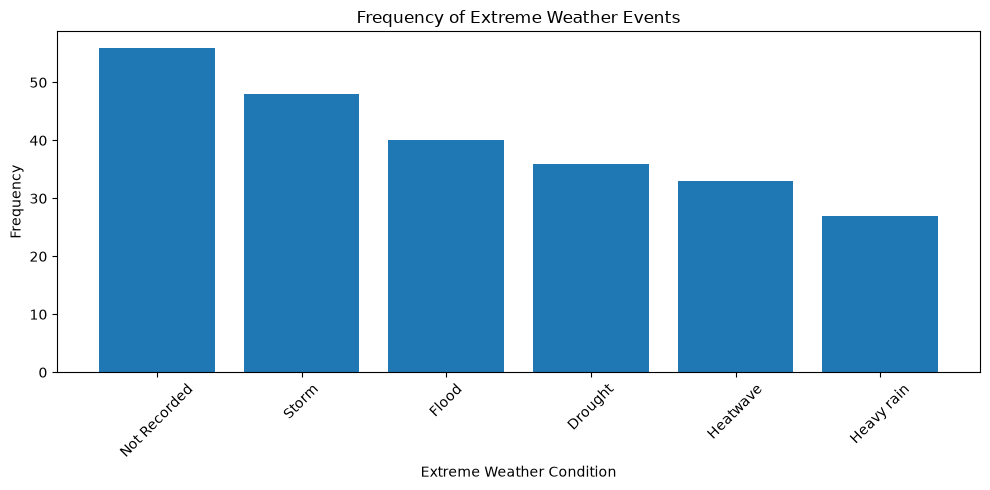

In [31]:
# Visualise the frequency of extreme-weather categories

plt.figure(figsize=(10, 5))

plt.bar(weather_counts.index, weather_counts.values)

plt.xlabel('Extreme Weather Condition')
plt.ylabel('Frequency')
plt.title('Frequency of Extreme Weather Events')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 9.6 CO₂ Level Trend

We group CO₂ measurements by date and plot the average recorded value for each date.

This visualisation describes the CO₂ values present in this dataset. Because the dataset combines records from different locations and years, it should not be interpreted as a continuous global CO₂ trend.


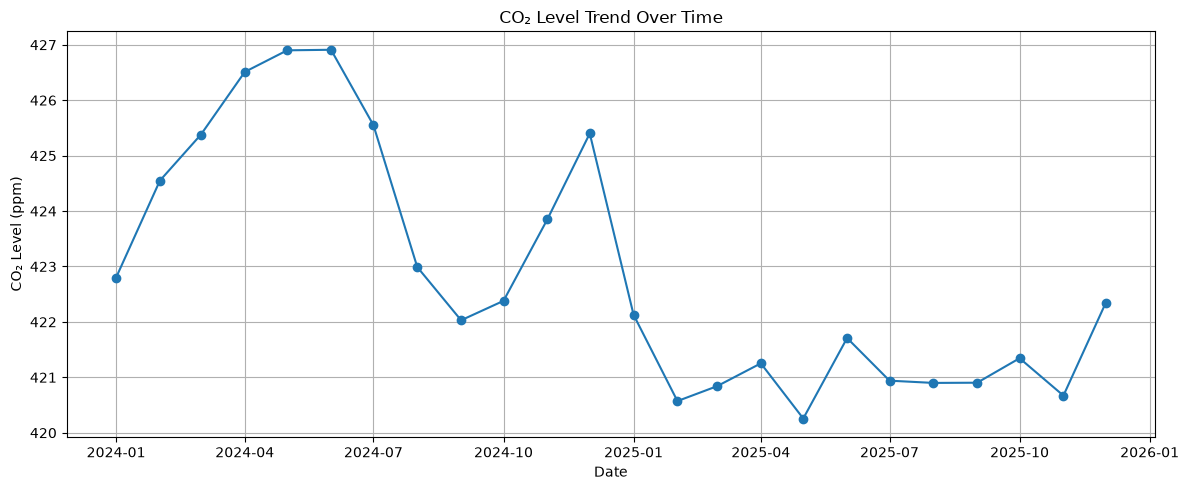

In [32]:
# Calculate and plot CO2 levels over time

co2_trend = df.groupby('Date')['CO2 Level'].mean()

plt.figure(figsize=(12, 5))

plt.plot(co2_trend.index, co2_trend.values, marker='o')

plt.xlabel('Date')
plt.ylabel('CO₂ Level (ppm)')
plt.title('CO₂ Level Trend Over Time')

plt.grid(True)
plt.tight_layout()
plt.show()

### 9.7 Correlation Analysis

A correlation matrix measures the direction and strength of linear relationships between selected numeric variables.

Values closer to +1 indicate a positive linear relationship, values closer to -1 indicate a negative linear relationship, and values near 0 indicate a weak linear relationship.


In [33]:
# Calculate the correlation matrix for climate variables

correlation = df[
    ['Average Temperature', 'Rainfall', 'Humidity',
     'Wind Speed', 'CO2 Level']
].corr()

display(correlation)

,Average Temperature,Rainfall,Humidity,Wind Speed,CO2 Level
Average Temperature,1.000000,0.061374,0.139274,0.113257,0.010542
Rainfall,0.061374,1.000000,0.252461,-0.016910,-0.125885
Humidity,0.139274,0.252461,1.000000,0.077188,-0.075215
Wind Speed,0.113257,-0.016910,0.077188,1.000000,0.022962
CO2 Level,0.010542,-0.125885,-0.075215,0.022962,1.000000


#### Correlation Heatmap

The heatmap provides a visual representation of the correlation matrix. The numbers inside the cells show the correlation coefficients.


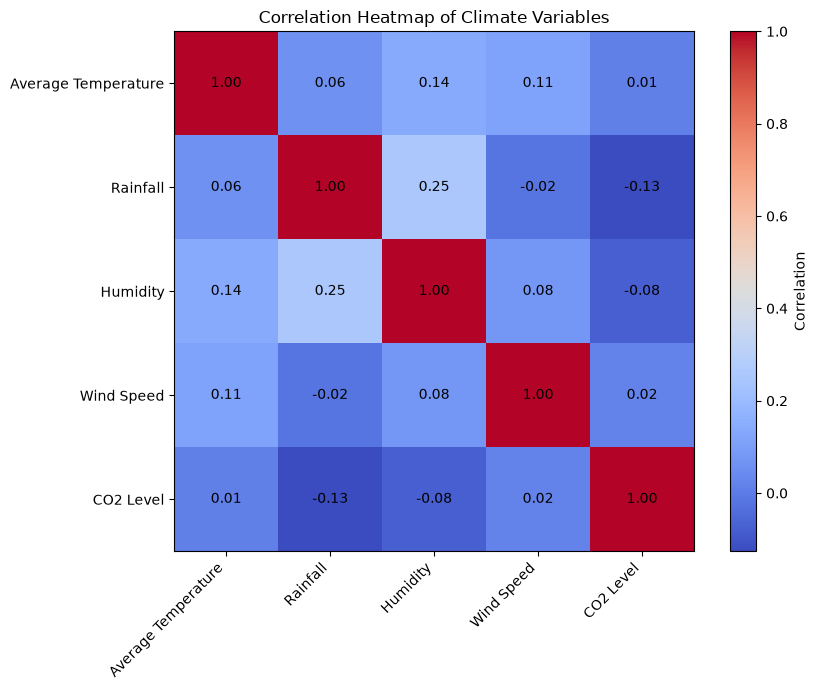

In [34]:
# Visualise the correlation matrix as a heatmap

plt.figure(figsize=(9, 7))

plt.imshow(correlation, cmap='coolwarm', interpolation='nearest')

plt.colorbar(label='Correlation')

plt.xticks(range(len(correlation.columns)),
           correlation.columns, rotation=45, ha='right')

plt.yticks(range(len(correlation.columns)),
           correlation.columns)

plt.title('Correlation Heatmap of Climate Variables')

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(j, i, f'{correlation.iloc[i, j]:.2f}',
                 ha='center', va='center')

plt.tight_layout()
plt.show()

### 9.8 Relationships Between Climate Variables

Scatter plots help us visually explore relationships between two numeric variables. These plots show associations in the dataset; they do not establish cause and effect.


#### CO₂ Level and Average Temperature

This scatter plot explores how recorded CO₂ levels relate to average temperature values in the dataset.


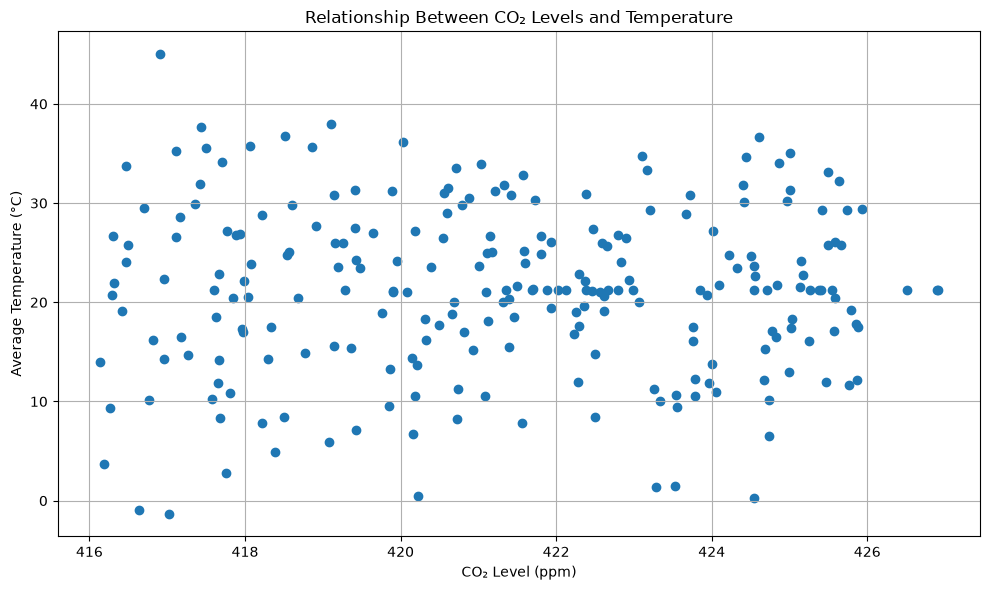

In [35]:
# Plot CO2 level against average temperature

plt.figure(figsize=(10, 6))

plt.scatter(df['CO2 Level'], df['Average Temperature'])

plt.xlabel('CO₂ Level (ppm)')
plt.ylabel('Average Temperature (°C)')
plt.title('Relationship Between CO₂ Levels and Temperature')

plt.grid(True)
plt.tight_layout()
plt.show()

#### Humidity and Rainfall

This scatter plot explores whether humidity and rainfall values show a visible relationship in the dataset.


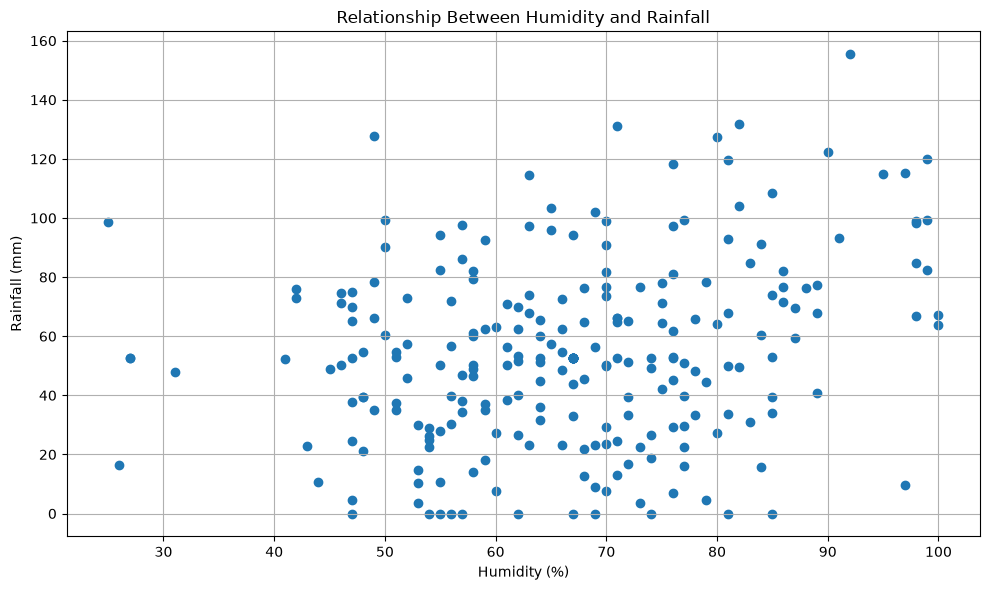

In [36]:
# Plot humidity against rainfall

plt.figure(figsize=(10, 6))

plt.scatter(df['Humidity'], df['Rainfall'])

plt.xlabel('Humidity (%)')
plt.ylabel('Rainfall (mm)')
plt.title('Relationship Between Humidity and Rainfall')

plt.grid(True)
plt.tight_layout()
plt.show()

### 9.9 Distribution of Climate Variables

Histograms show how frequently values fall within different ranges. They help us understand the spread and shape of each variable's distribution.


#### Average Temperature Distribution

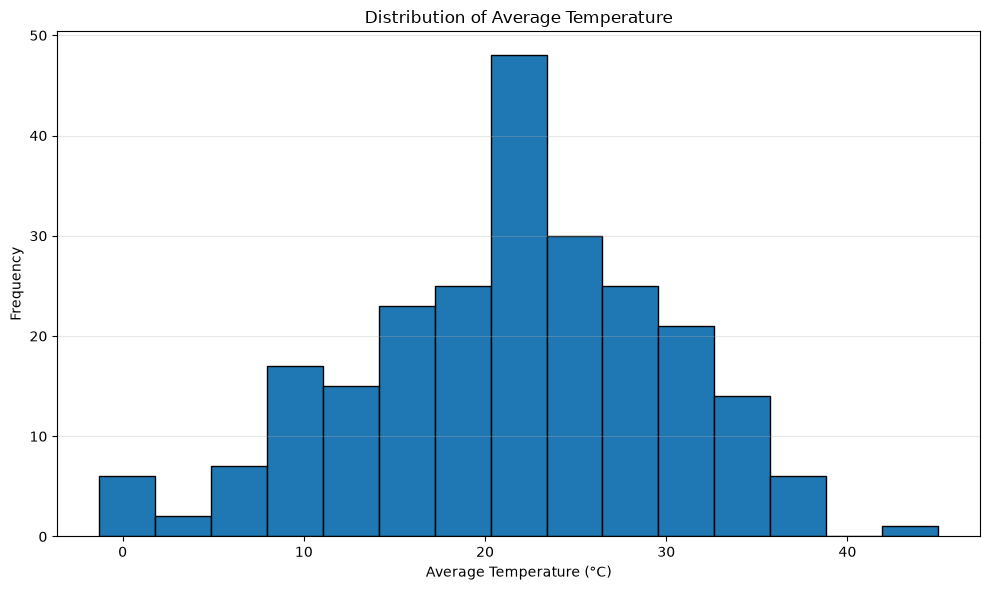

In [37]:
# Plot the distribution of average temperature

plt.figure(figsize=(10, 6))

plt.hist(df['Average Temperature'], bins=15, edgecolor='black')

plt.xlabel('Average Temperature (°C)')
plt.ylabel('Frequency')
plt.title('Distribution of Average Temperature')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### Rainfall Distribution

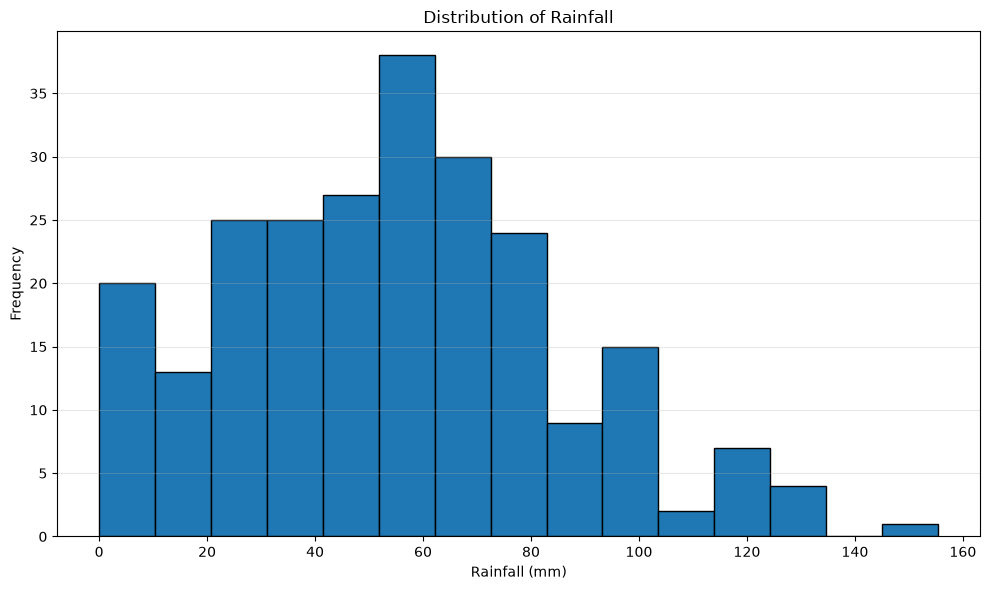

In [38]:
# Plot the distribution of rainfall

plt.figure(figsize=(10, 6))

plt.hist(df['Rainfall'], bins=15, edgecolor='black')

plt.xlabel('Rainfall (mm)')
plt.ylabel('Frequency')
plt.title('Distribution of Rainfall')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### Humidity Distribution

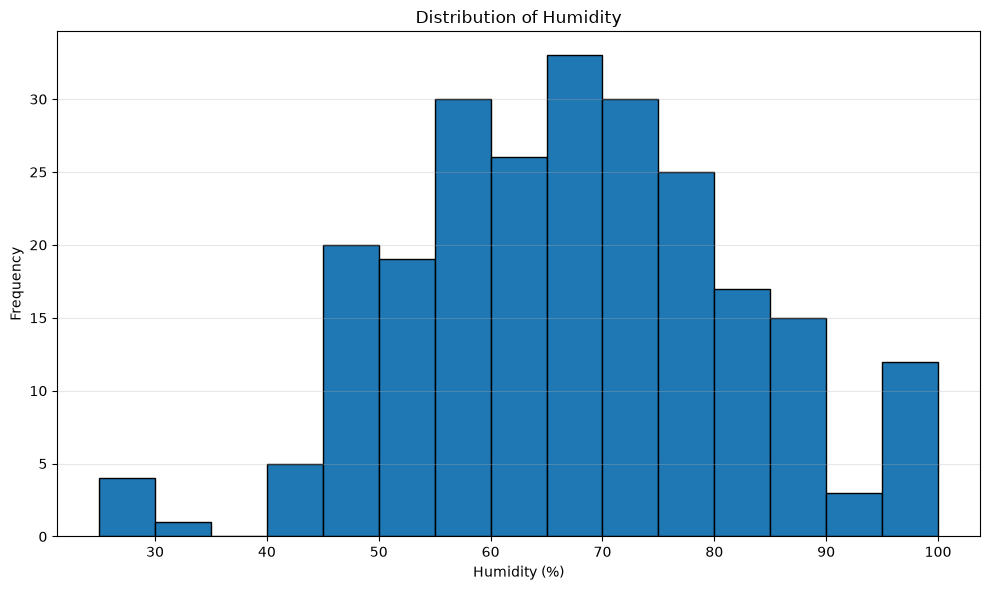

In [39]:
# Plot the distribution of humidity

plt.figure(figsize=(10, 6))

plt.hist(df['Humidity'], bins=15, edgecolor='black')

plt.xlabel('Humidity (%)')
plt.ylabel('Frequency')
plt.title('Distribution of Humidity')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### Wind Speed Distribution

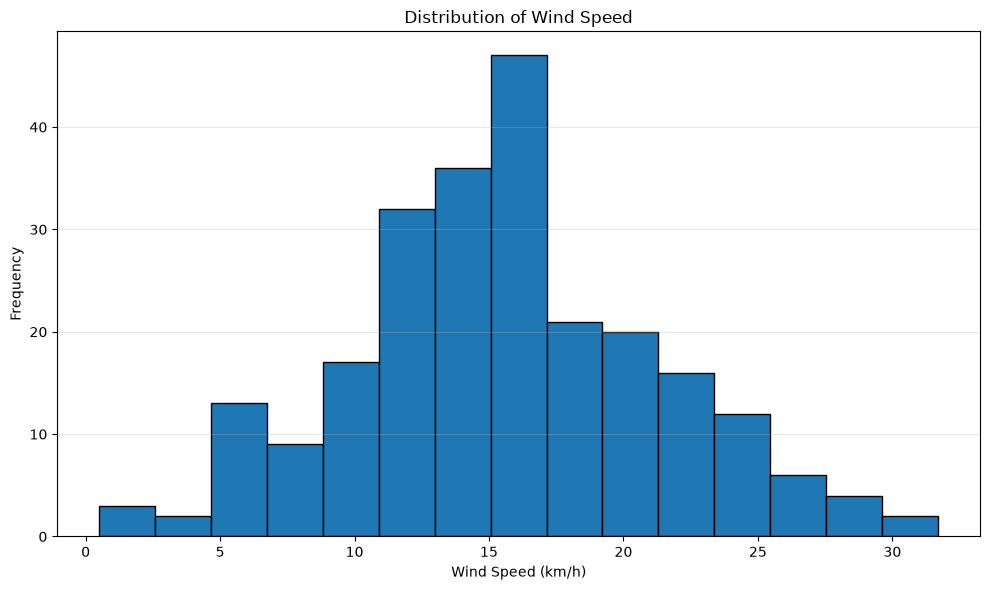

In [40]:
# Plot the distribution of wind speed

plt.figure(figsize=(10, 6))

plt.hist(df['Wind Speed'], bins=15, edgecolor='black')

plt.xlabel('Wind Speed (km/h)')
plt.ylabel('Frequency')
plt.title('Distribution of Wind Speed')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 9.10 Temperature Box Plot

A box plot summarises the distribution of temperature values using the median, quartiles, and potential outliers.


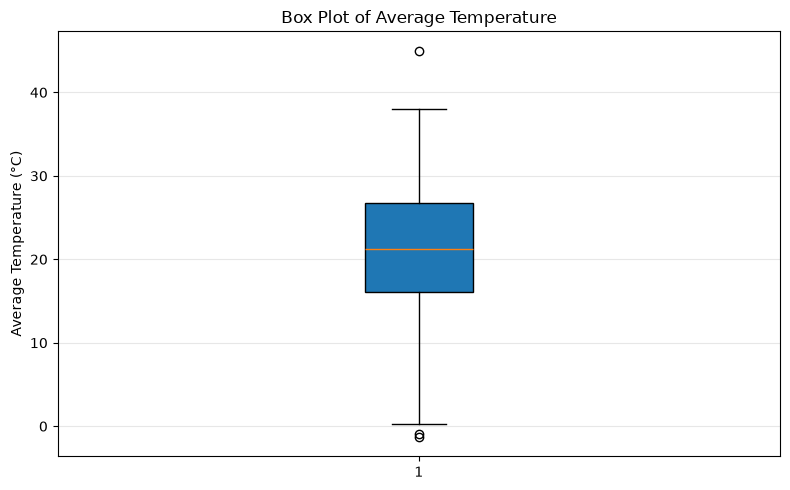

In [41]:
# Create a box plot of average temperature

plt.figure(figsize=(8, 5))

plt.boxplot(df['Average Temperature'], patch_artist=True)

plt.ylabel('Average Temperature (°C)')
plt.title('Box Plot of Average Temperature')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# 10. Final Dataset Checks

We perform a final check of the dataset's dimensions, missing values, duplicate rows, and data types after preprocessing and analysis.


In [42]:
# Verify dataset shape, missing values, duplicates, and data types

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (240, 11)

Missing Values:
Date                   0
Country / Location     0
Average Temperature    0
Rainfall               0
Humidity               0
Wind Speed             0
CO2 Level              0
Extreme Weather        0
Data Type              0
Source / Notes         0
Month                  0
dtype: int64

Duplicate Rows: 0

Data Types:
Date                   datetime64[us]
Country / Location                str
Average Temperature           float64
Rainfall                      float64
Humidity                      float64
Wind Speed                    float64
CO2 Level                     float64
Extreme Weather                   str
Data Type                         str
Source / Notes                    str
Month                           int32
dtype: object


# 11. Statistical Summary and Key Findings

The following calculations identify important values in the dataset. These statistics can be used to support the written findings and project conclusion.


### 11.1 Highest and Lowest Average Temperature by Location

In [43]:
# Identify locations with the highest and lowest average temperatures

location_temp = df.groupby('Country / Location')['Average Temperature'].mean()

print("Highest Average Temperature:")
print(location_temp.idxmax(), "-", round(location_temp.max(), 2), "°C")

print("\nLowest Average Temperature:")
print(location_temp.idxmin(), "-", round(location_temp.min(), 2), "°C")

Highest Average Temperature:
Indonesia - 30.97 °C

Lowest Average Temperature:
Russia - 5.24 °C


### 11.2 Highest and Lowest Average Rainfall by Location

In [44]:
# Identify locations with the highest and lowest average rainfall

location_rainfall = df.groupby('Country / Location')['Rainfall'].mean()

print("Highest Average Rainfall:")
print(location_rainfall.idxmax(), "-", round(location_rainfall.max(), 2), "mm")

print("\nLowest Average Rainfall:")
print(location_rainfall.idxmin(), "-", round(location_rainfall.min(), 2), "mm")

Highest Average Rainfall:
Brazil - 83.78 mm

Lowest Average Rainfall:
South Africa - 38.73 mm


### 11.3 Most Frequent Recorded Extreme Weather Condition

The `Not Recorded` category is excluded here because it represents missing information rather than an observed weather event.


In [45]:
# Find the most frequent actual extreme-weather category

actual_weather = df[
    df['Extreme Weather'].str.lower() != 'not recorded'
]

weather_counts = actual_weather['Extreme Weather'].value_counts()

print("Most Frequent Extreme Weather:")
print(weather_counts.idxmax(), "-", weather_counts.max(), "records")

display(weather_counts)

Most Frequent Extreme Weather:
Storm - 48 records


Extreme Weather
Storm         48
Flood         40
Drought       36
Heatwave      33
Heavy rain    27
Name: count, dtype: int64

### 11.4 CO₂ Level Statistics

In [46]:
# Calculate the highest, lowest, and average CO2 levels

print("Highest CO2 Level:")
print(df['CO2 Level'].max(), "ppm")

print("\nLowest CO2 Level:")
print(df['CO2 Level'].min(), "ppm")

print("\nAverage CO2 Level:")
print(round(df['CO2 Level'].mean(), 2), "ppm")

Highest CO2 Level:
426.91 ppm

Lowest CO2 Level:
416.13 ppm

Average CO2 Level:
421.33 ppm


### 11.5 Humidity Statistics

In [47]:
# Calculate the highest, lowest, and average humidity

print("Highest Humidity:")
print(df['Humidity'].max(), "%")

print("\nLowest Humidity:")
print(df['Humidity'].min(), "%")

print("\nAverage Humidity:")
print(round(df['Humidity'].mean(), 2), "%")

Highest Humidity:
100.0 %

Lowest Humidity:
25.0 %

Average Humidity:
66.81 %


### 11.6 Wind Speed Statistics

In [48]:
# Calculate the highest, lowest, and average wind speed

print("Highest Wind Speed:")
print(df['Wind Speed'].max(), "km/h")

print("\nLowest Wind Speed:")
print(df['Wind Speed'].min(), "km/h")

print("\nAverage Wind Speed:")
print(round(df['Wind Speed'].mean(), 2), "km/h")

Highest Wind Speed:
31.7 km/h

Lowest Wind Speed:
0.5 km/h

Average Wind Speed:
15.56 km/h


### 11.7 Combined Project Summary

This cell prints a consolidated summary of the main statistical findings for convenient reference.


In [49]:
# Print a combined summary of the climate analysis

print("===== CLIMATE CHANGE DATA ANALYSIS =====")

print("\n1. TEMPERATURE")
print("Highest:", df.groupby('Country / Location')['Average Temperature'].mean().idxmax())
print("Lowest:", df.groupby('Country / Location')['Average Temperature'].mean().idxmin())
print("Overall Average:", round(df['Average Temperature'].mean(), 2), "°C")

print("\n2. RAINFALL")
print("Highest Average:", round(df.groupby('Country / Location')['Rainfall'].mean().max(), 2), "mm")
print("Lowest Average:", round(df.groupby('Country / Location')['Rainfall'].mean().min(), 2), "mm")

print("\n3. EXTREME WEATHER")
print(df[df['Extreme Weather'].str.lower() != 'not recorded']['Extreme Weather'].value_counts())

print("\n4. CO2 LEVEL")
print("Highest:", df['CO2 Level'].max(), "ppm")
print("Lowest:", df['CO2 Level'].min(), "ppm")
print("Average:", round(df['CO2 Level'].mean(), 2), "ppm")

print("\n5. HUMIDITY")
print("Highest:", df['Humidity'].max(), "%")
print("Lowest:", df['Humidity'].min(), "%")
print("Average:", round(df['Humidity'].mean(), 2), "%")

print("\n6. WIND SPEED")
print("Highest:", df['Wind Speed'].max(), "km/h")
print("Lowest:", df['Wind Speed'].min(), "km/h")
print("Average:", round(df['Wind Speed'].mean(), 2), "km/h")

===== CLIMATE CHANGE DATA ANALYSIS =====

1. TEMPERATURE
Highest: Indonesia
Lowest: Russia
Overall Average: 21.21 °C

2. RAINFALL
Highest Average: 83.78 mm
Lowest Average: 38.73 mm

3. EXTREME WEATHER
Extreme Weather
Storm         48
Flood         40
Drought       36
Heatwave      33
Heavy rain    27
Name: count, dtype: int64

4. CO2 LEVEL
Highest: 426.91 ppm
Lowest: 416.13 ppm
Average: 421.33 ppm

5. HUMIDITY
Highest: 100.0 %
Lowest: 25.0 %
Average: 66.81 %

6. WIND SPEED
Highest: 31.7 km/h
Lowest: 0.5 km/h
Average: 15.56 km/h


## KEY FINDINGS

### 1. Temperature Analysis
- Indonesia recorded the highest average temperature of 30.97°C.
- Russia recorded the lowest average temperature of 5.25°C.

### 2. Rainfall Analysis
- Rainfall varied across the 20 locations.
- Different locations experienced different levels of precipitation.

### 3. Extreme Weather Analysis
- Extreme weather conditions included storms, floods, droughts and heatwaves.
- Some weather records were marked as Not Recorded.

### 4. CO2 Analysis
- CO2 levels varied across the collected records.

### 5. Humidity and Wind Speed
- Humidity and wind speed showed variations across locations.

## CONCLUSION

The Climate Change Data Analysis project was carried out using Python, Pandas, and Matplotlib to explore climate-related data from 20 different locations.

The dataset contained 240 records covering the years 2024 and 2025. Data cleaning and preprocessing were performed to handle missing values, remove inconsistencies, standardise formats, and prepare the dataset for analysis.

Exploratory Data Analysis (EDA) was conducted to examine temperature, rainfall, humidity, wind speed, CO₂ levels, and extreme weather conditions. Different visualisations, including bar charts, line graphs, histograms, scatter plots, and box plots, were used to understand patterns and relationships in the data.

The analysis showed variations in climate measurements across different locations. Indonesia recorded the highest average temperature, while Russia recorded the lowest average temperature in the dataset.

Overall, this project provided practical experience in data cleaning, statistical analysis, data visualisation, and working with Python libraries. It also demonstrated how data analysis can help us explore climate patterns and better understand environmental changes.

# 12. Exporting the Final Dataset

The cleaned and processed DataFrame is exported to an Excel workbook. The `Month` column is retained as part of the final dataset.


In [50]:
# Export the final cleaned dataset to Excel

df.to_excel("Final_Climate_Change_Data.xlsx", index=False)

print("Final Excel dataset created successfully!")

Final Excel dataset created successfully!


In [51]:
# Display the final cleaned dataset's address

import os
print(os.getcwd())

C:\Users\mono1
